# US Baby Name

## GIỚI THIỆU
Dữ Liệu `US_BaBy_Names.csv` chứa thông tin của các em bé sinh từ 2004 - 2014 tại Mỹ. Dựa vào tập dữ liệu trên, bạn hãy thực hiện các bài tập sau:

## TÌM HIỂU DỮ LIỆU

### 01. Đọc dữ liệu

In [26]:
import pandas as pd
import numpy as np

In [27]:
df = pd.read_csv('T:/TKMT/TKMT_lab_02/US_Baby_Names.csv', header = 0)

### 02. Hiển thị 10 dòng dữ liệu bất kỳ

In [28]:
df.head(10)

,Unnamed: 0,Id,Name,Year,Gender,State,Count
0,11349,11350,Emma,2004,F,AK,62
1,11350,11351,Madison,2004,F,AK,48
2,11351,11352,Hannah,2004,F,AK,46
3,11352,11353,Grace,2004,F,AK,44
4,11353,11354,Emily,2004,F,AK,41
5,11354,11355,Abigail,2004,F,AK,37
6,11355,11356,Olivia,2004,F,AK,33
7,11356,11357,Isabella,2004,F,AK,30
8,11357,11358,Alyssa,2004,F,AK,29
9,11358,11359,Sophia,2004,F,AK,28


### 03. Cho biết kích thước dữ liệu

In [29]:
df.shape

(1016395, 7)

### 04. Xóa 2 cột 'Unnamed: 0' and 'Id'

In [30]:
df = df.drop(columns = ['Unnamed: 0', 'Id'])
#thêm errors='ignore': sẽ bỏ qua cột nào ko tồn tại

### 05. Cho biết số lượng bé trai, bé gái?

In [36]:
df['Gender'].value_counts()

F    558846
M    457549
Name: Gender, dtype: int64

### 06. Trong bộ dữ liệu có bao nhiêu tên khác nhau?

In [37]:
df.nunique()

Name      17632
Year         11
Gender        2
State        51
Count      1949
dtype: int64

### 07. Tên nào xuất hiện ít nhất?

In [38]:
df['Name'].value_counts().tail()
#.tail(): lấy từ dưới lấy lên

Sayvion      1
Torianna     1
Jamicheal    1
Dinora       1
Brek         1
Name: Name, dtype: int64

### 08. Top 10 tên được sử dụng nhiều nhất?

In [39]:
df['Name'].value_counts().head(10)

Riley     1112
Avery     1080
Jordan    1073
Peyton    1064
Hayden    1049
Taylor    1033
Jayden    1031
Alexis     984
Payton     971
Dakota     962
Name: Name, dtype: int64

## TRỰC QUAN DỮ LIỆU

### 09. Vẽ đồ thị top 10 tên xuất hiện nhiều nhất năm 2014

In [41]:
import matplotlib.pyplot as plt

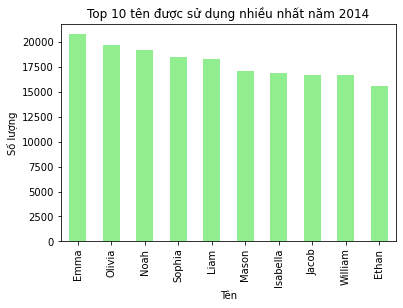

In [53]:
# Lấy dữ liệu năm 2014
data = df[df['Year'] == 2014]

# Tính tổng số lượng theo tên
data = data.groupby('Name')['Count'].sum()

# Sắp xếp từ lớn đến nhỏ và lấy 10 tên đầu
data = data.sort_values(ascending=False).head(10)

# Vẽ biểu đồ
data.plot(kind='bar', color = 'lightgreen')

plt.title('Top 10 tên được sử dụng nhiều nhất năm 2014')
plt.xlabel('Tên')
plt.ylabel('Số lượng')
plt.show()

### 10. Vẽ đồ thị thể hiện tỷ lệ nam nữ qua các năm 2004-2014

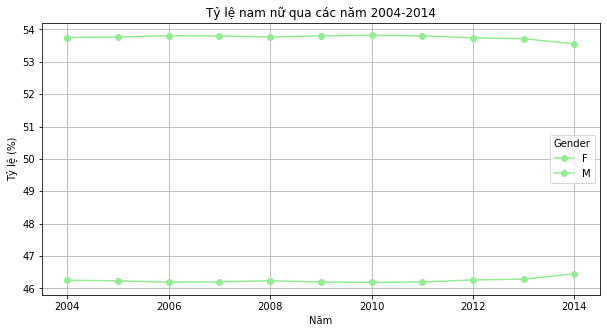

In [54]:
# Lấy dữ liệu từ năm 2004 đến 2014
data = df[(df['Year'] >= 2004) & (df['Year'] <= 2014)]

# Tính tổng số bé trai và bé gái theo từng năm
gender = data.groupby(['Year', 'Gender'])['Count'].sum().unstack()

# Tính tỷ lệ nam và nữ (%)
gender_percent = gender.div(gender.sum(axis=1), axis=0) * 100

# Vẽ biểu đồ
gender_percent.plot(kind='line', marker='o', figsize=(10, 5), color='lightgreen')

plt.title('Tỷ lệ nam nữ qua các năm 2004-2014')
plt.xlabel('Năm')
plt.ylabel('Tỷ lệ (%)')

plt.grid()
plt.show()